# Анализ E1: что нашла автоматика и почему это работает

Анализ на **val_b** (не участвовала ни в отборе признаков, ни в выборе числа деревьев). Модели и предсказания — из `artifacts/E1/` (ноутбук `03_E1_autofeatures_training`).

**Вопросы:**
1. Как финальная модель E1 использует признаки — между пользователями или внутри (как в анализе E0)?
2. Что в E1 **нового** по сравнению с E0, а что — те же признаки в другой форме? Это объясняет, почему E0 + E1 лучше E0.
3. Калибровка: насколько хуже вероятности у E1 (он хуже по LogLoss).
4. Сегменты: где E1 выигрывает или проигрывает у E0 (холодные пользователи, новые и редкие треки).
5. **Стабильность отбора:** если запустить всю воронку на другой подвыборке, получим ли те же признаки и то же качество?

In [ ]:
import sys, time, resource, pickle
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def peak_ram_gb():
    """Пиковая память процесса (ядра ноутбука) с момента старта, ГБ."""
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2

import json
import shap
from sklearn.metrics import roc_auc_score, log_loss
from src.candidates import load_candidates
from src.features import E0_FEATURES
from src.metrics import evaluate
from src.selection import catalog, load_matrix, fit_light

ART, ART0 = ROOT / "artifacts" / "E1", ROOT / "artifacts" / "E0"
res = pickle.load(open(ART / "results.pkl", "rb"))
res0 = pickle.load(open(ART0 / "results.pkl", "rb"))
lgb_e1 = pickle.load(open(ART / "lgb.pkl", "rb"))
F1 = res["features"]
cat = catalog()

cands = load_candidates()
vb_c = cands.filter(pl.col("part") == "val_b")
feats0 = pl.read_parquet(ROOT / "data" / "processed" / "features_E0.parquet")

vb = (res["predictions"].filter(pl.col("part") == "val_b")
      .join(res0["predictions"].filter(pl.col("part") == "val_b").select("row_id", pl.col("p_lgb").alias("p_E0")),
            on="row_id", how="left", maintain_order="left"))

X1 = load_matrix(vb_c, F1, cat)

vb = (vb.join(X1, on="row_id", how="left", maintain_order="left")
        .join(feats0, on="row_id", how="left", maintain_order="left"))

print(f"val_b: {vb.height:,} строк; признаки E1: {F1}".replace(",", " "))
display(res["metrics"].filter(pl.col("часть") == "val_b").with_columns(pl.col(pl.Float64).round(4)))

.../site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


val_b: 725 211 строк; признаки E1: ['ui__all_full__all'  'i__all_srate__all'  'u__reco_skip__all'  'ui__all_played__90d'  'ul__reco_srate__all'  'ua__all_played__all'  'ua__reco_full__all'  'ui__reco_srate__all'  'i__reco_srate__90d'  'ui__all_full__90d']


модель,часть,logloss,roc_auc,ndcg@10,recall@10,gauc,groups
str,str,f64,f64,f64,f64,f64,i64
"""E0 LightGBM""","""val_b""",0.4558,0.8254,0.7651,0.5104,0.569,15622
"""E0 логрегрессия""","""val_b""",0.4651,0.8192,0.7577,0.5062,0.5623,15622
"""E1 LightGBM""","""val_b""",0.4633,0.819,0.7645,0.51,0.5692,15622
"""E0 + E1 LightGBM""","""val_b""",0.4524,0.8286,0.7672,0.512,0.5733,15622
"""E1 логрегрессия""","""val_b""",0.4703,0.8144,0.7581,0.5061,0.5633,15622


## 1. SHAP: вклад между пользователями и внутри пользователя

Тот же приём, что в анализе E0: берём 2 000 **целых** групп «пользователь × день» и для каждого признака считаем
- **общий вклад** — std SHAP по всем строкам;
- **вклад внутри группы** — std SHAP внутри группы, усреднённое по группам. Только эта часть меняет порядок треков у одного пользователя.

.../site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


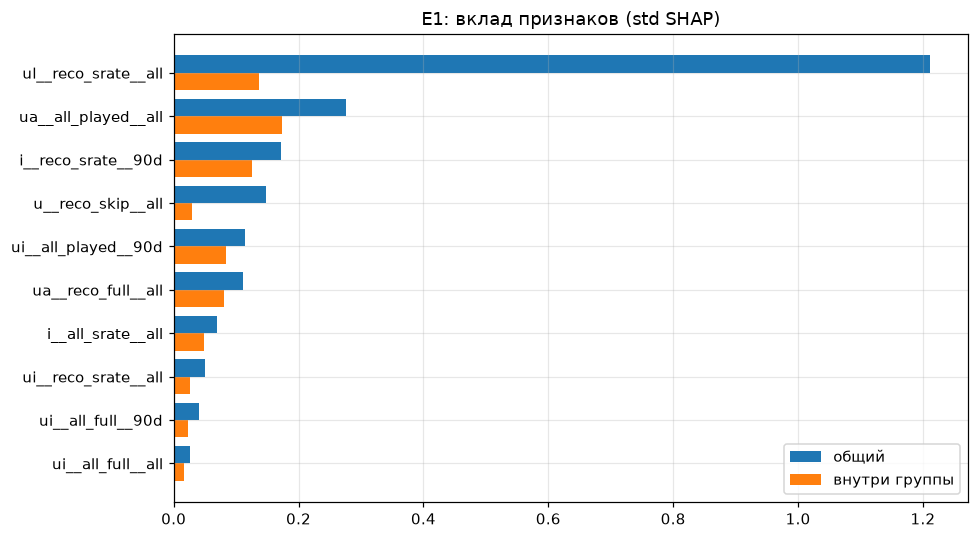

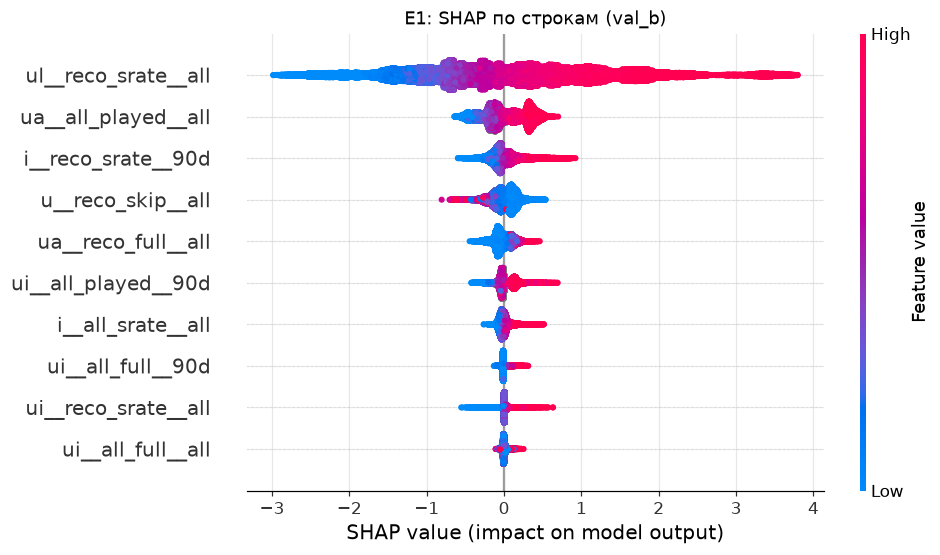

признак,общий,внутри группы,доля внутри
str,f64,f64,f64
"""ul__reco_srate__all""",1.212,0.137,0.113
"""ua__all_played__all""",0.275,0.173,0.629
"""i__reco_srate__90d""",0.172,0.125,0.727
"""u__reco_skip__all""",0.147,0.029,0.197
"""ui__all_played__90d""",0.115,0.084,0.735
"""ua__reco_full__all""",0.112,0.081,0.725
"""i__all_srate__all""",0.069,0.049,0.707
"""ui__reco_srate__all""",0.05,0.026,0.522
"""ui__all_full__90d""",0.04,0.023,0.565


In [ ]:
rng = np.random.default_rng(0)
groups = vb.select("uid", "day").unique().sort("uid", "day")
pick = groups[rng.choice(groups.height, 2000, replace=False)]
sample = vb.join(pick, on=["uid", "day"]).sort("uid", "day")

Xs = sample.select(F1).to_numpy()
sv = shap.TreeExplainer(lgb_e1).shap_values(Xs)
sv = sv[1] if isinstance(sv, list) else sv

S = pl.DataFrame(sv, schema=F1).with_columns(sample.select("uid", "day"))
dec = (pl.DataFrame({"признак": F1,
                     "общий": S.select(pl.col(F1).std()).row(0),
                     "внутри группы": S.group_by("uid", "day").agg(pl.col(F1).std()).select(pl.col(F1).mean()).row(0)})
       .with_columns((pl.col("внутри группы") / pl.col("общий")).alias("доля внутри"))
       .sort("общий", descending=True))

fig, ax = plt.subplots(figsize=(9, 5))
d = dec.reverse()
y = np.arange(d.height)


ax.barh(y + 0.2, d["общий"], height=0.4, label="общий")
ax.barh(y - 0.2, d["внутри группы"], height=0.4, label="внутри группы")
ax.set_yticks(y, d["признак"])
ax.legend()
ax.set_title("E1: вклад признаков (std SHAP)")

plt.tight_layout()
plt.show()
shap.summary_plot(sv, Xs, feature_names=F1, show=False, plot_size=(9, 5))
plt.title("E1: SHAP по строкам (val_b)")
plt.show()
display(dec.with_columns(pl.col(pl.Float64).round(3)))

- у признаков пользователя (`u__…`) «доля внутри» близка к нулю — они одинаковы у всех треков пользователя за день и ранжировать не могут; их роль — поправлять уровень вероятности (и через взаимодействия — насколько доверять признакам трека)
- Признаки пары «пользователь × трек / артист» и трека работают в основном **внутри** группы.

## 2. Что в E1 нового по сравнению с E0

Для каждого признака E1 ищем самый похожий признак E0 — по ранговой корреляции Спирмена (пропуски = −1, «нет истории»). Если |ρ| ≈ 1 — это тот же признак E0 в другой форме; если заметно меньше — новая информация.

In [ ]:
smp = vb.sample(200_000, seed=0)
both = smp.select(*F1, *E0_FEATURES).fill_null(-1).with_columns(pl.all().rank("average"))

A = both.select(F1).to_numpy()
B = both.select(E0_FEATURES).to_numpy()

A = (A - A.mean(0)) / A.std(0)
B = (B - B.mean(0)) / (B.std(0) + 1e-12)
C = A.T @ B / len(A)

best = np.abs(C).argmax(1)
sim = (pl.DataFrame({"признак E1": F1, "ближайший в E0": [E0_FEATURES[j] for j in best],
                     "|ρ|": np.abs(C)[np.arange(len(F1)), best].round(3)})
       .join(dec.select(pl.col("признак").alias("признак E1"), pl.col("внутри группы").round(3)), on="признак E1",
             maintain_order="left"))
sim

признак E1,ближайший в E0,|ρ|,внутри группы
str,str,f64,f64
"""ui__all_full__all""","""ui_full_all""",1.0,0.016
"""i__all_srate__all""","""i_full_rate_all""",0.972,0.049
"""u__reco_skip__all""","""u_listen_all""",0.67,0.029
"""ui__all_played__90d""","""ui_full_all""",0.754,0.084
"""ul__reco_srate__all""","""u_reco_full_rate_30d""",0.903,0.137
"""ua__all_played__all""","""ua_full_rate_all""",0.986,0.173
"""ua__reco_full__all""","""ua_listen_all""",0.905,0.081
"""ui__reco_srate__all""","""ui_full_all""",0.569,0.026
"""i__reco_srate__90d""","""i_full_rate_all""",0.809,0.125


Признаки с |ρ| заметно меньше 0.9 — то, чего ручной набор не покрывает (обычно другое окно, срез только по рекомендациям или новый ключ). Именно они дают прирост E0 + E1 над E0 (+0.004 GAUC, значимо).

## 3. Калибровка

E1 хуже по LogLoss (0.463 против 0.456). Проверяем, в чём дело: в плохой калибровке (сдвиг вероятностей) или в меньшей различающей силе.

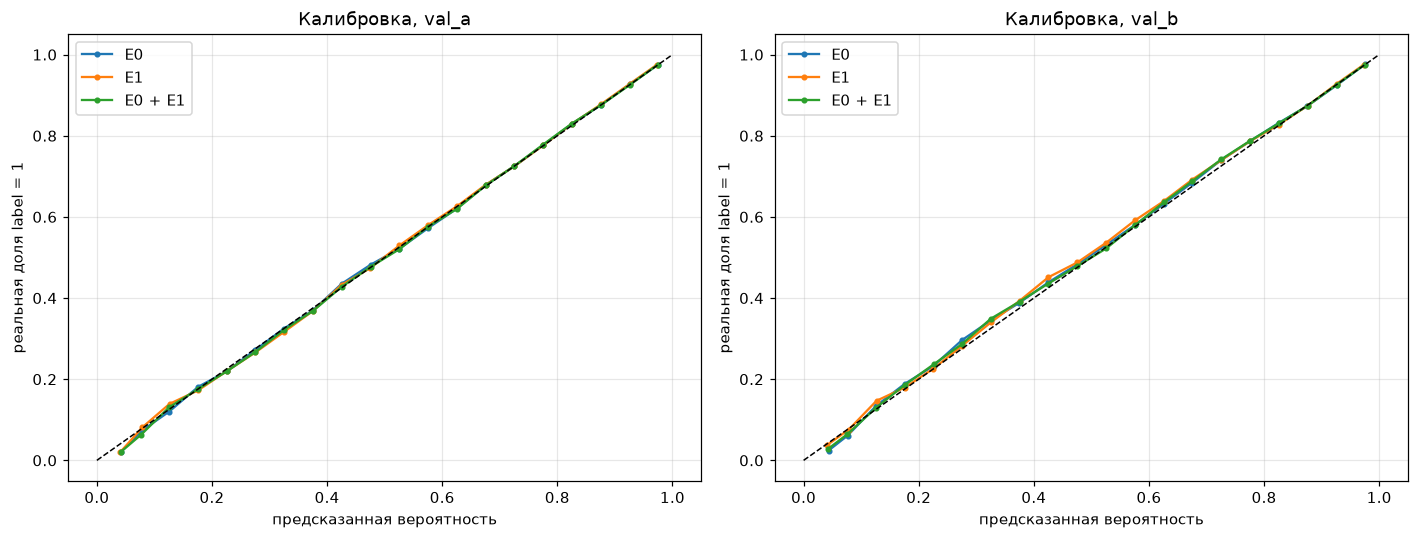

модель,часть,средний прогноз,реальная доля,std прогноза
str,str,f64,f64,f64
"""E0""","""val_a""",0.6885,0.6887,0.2521
"""E1""","""val_a""",0.6876,0.6887,0.2444
"""E0 + E1""","""val_a""",0.6892,0.6887,0.2534
"""E0""","""val_b""",0.6944,0.7003,0.2497
"""E1""","""val_b""",0.6922,0.7003,0.2446
"""E0 + E1""","""val_b""",0.6945,0.7003,0.2515


In [ ]:
preds = res["predictions"].join(res0["predictions"].select("row_id", pl.col("p_lgb").alias("p_E0")), on="row_id",
                                 how="left", maintain_order="left")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

rows = []
for ax, p in zip(axes, ["val_a", "val_b"]):
    d = preds.filter(pl.col("part") == p)
    
    for name, col in [("E0", "p_E0"), ("E1", "p_E1"), ("E0 + E1", "p_E0 + E1")]:
        
        cal = (d.with_columns((pl.col(col) * 20).floor().clip(0, 19).alias("bin"))
               .group_by("bin").agg(pl.col(col).mean().alias("pred"), pl.col("label").mean().alias("true"), pl.len().alias("n"))
               .sort("bin"))
        
        ax.plot(cal["pred"], cal["true"], "o-", ms=3, label=name)
        rows.append({"модель": name, "часть": p, "средний прогноз": d[col].mean(), "реальная доля": d["label"].mean(),
                     "std прогноза": d[col].std()})
    
    
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"Калибровка, {p}")
    ax.set_xlabel("предсказанная вероятность")
    ax.set_ylabel("реальная доля label = 1")
    ax.legend()


plt.tight_layout()
plt.show()
pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(4))

Если кривые E1 лежат на диагонали, а «std прогноза» меньше, чем у E0, — модель **откалибрована, но менее уверенна**: ей не хватает признаков уровня пользователя, которые разводят «дослушивающих» и «скипающих» далеко по вероятности. Это ожидаемая цена отбора по GAUC.

## 4. Сегменты: где E1 выигрывает и где проигрывает

Сегменты те же, что в анализе E0 (их задают признаки E0, чтобы сравнение было одинаковым для всех моделей):
- **история пользователя** (`u_listen_all`) — группа «пользователь × день» целиком попадает в один сегмент, поэтому считаем групповые метрики (GAUC, NDCG);
- **знакомость трека** и **популярность трека** — делят группы, поэтому только ROC-AUC и LogLoss.

сегмент,доля строк,GAUC E0,GAUC E1,GAUC E0 + E1,E1 − E0
str,f64,f64,f64,f64,f64
"""история польз.: a) < 500""",0.043,0.5273,0.5178,0.5234,-0.0095
"""история польз.: b) 500–2k""",0.126,0.5441,0.545,0.551,0.0009
"""история польз.: c) 2k–8k""",0.385,0.5692,0.5711,0.5747,0.0019
"""история польз.: d) > 8k""",0.446,0.5859,0.5852,0.5889,-0.0007


сегмент,доля строк,ROC-AUC E0,ROC-AUC E1,ROC-AUC E0 + E1,E1 − E0
str,f64,f64,f64,f64,f64
"""трек для польз.: знакомый""",0.591,0.825,0.8174,0.827,-0.0076
"""трек для польз.: новый""",0.409,0.8227,0.8175,0.8274,-0.0052
"""популярность трека: a) < 10""",0.058,0.8611,0.8521,0.8623,-0.009
"""популярность трека: b) 10–100""",0.139,0.8517,0.8443,0.8541,-0.0074
"""популярность трека: c) 100–1k""",0.371,0.8313,0.8248,0.8345,-0.0065
"""популярность трека: d) > 1k""",0.432,0.8054,0.8,0.8091,-0.0054


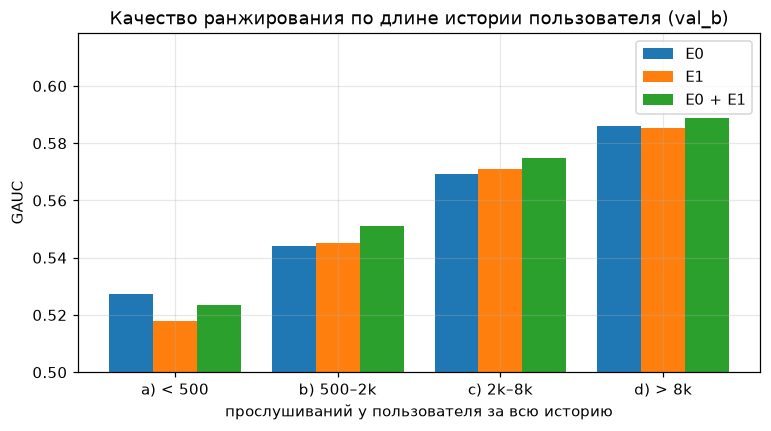

In [ ]:
def bucket(col, edges, labels):
    e = pl.lit(labels[-1])
    for edge, lab in reversed(list(zip(edges, labels[:-1]))):
        e = pl.when(pl.col(col) <= edge).then(pl.lit(lab)).otherwise(e)
    return e

MODELS = [("E0", "p_E0"), ("E1", "p_E1"), ("E0 + E1", "p_E0 + E1")]

def seg_table(seg_expr, name, ranking):
    out = []
    d = vb.with_columns(seg=seg_expr)
    for s in d["seg"].unique().sort().to_list():
        x = d.filter(pl.col("seg") == s)
        row = {"сегмент": f"{name}: {s}", "доля строк": round(x.height / vb.height, 3)}
        for m, col in MODELS:
            if ranking:
                row[f"GAUC {m}"] = round(evaluate(x, col)["gauc"], 4)
            else:
                row[f"ROC-AUC {m}"] = round(roc_auc_score(x["label"].to_numpy(), x[col].to_numpy()), 4)
        out.append(row)
    return pl.DataFrame(out)

seg_u = seg_table(bucket("u_listen_all", [500, 2000, 8000], ["a) < 500", "b) 500–2k", "c) 2k–8k", "d) > 8k"]), "история польз.", True)
seg_t = pl.concat([
    seg_table(pl.when(pl.col("ui_listen_all") > 0).then(pl.lit("знакомый")).otherwise(pl.lit("новый")), "трек для польз.", False),
    seg_table(bucket("i_listen_all", [10, 100, 1000], ["a) < 10", "b) 10–100", "c) 100–1k", "d) > 1k"]), "популярность трека", False)])
display(seg_u.with_columns((pl.col("GAUC E1") - pl.col("GAUC E0")).round(4).alias("E1 − E0")))
display(seg_t.with_columns((pl.col("ROC-AUC E1") - pl.col("ROC-AUC E0")).round(4).alias("E1 − E0")))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(seg_u.height)

for i, (m, _) in enumerate(MODELS):
    ax.bar(x + (i - 1) * 0.27, seg_u[f"GAUC {m}"], width=0.27, label=m)


ax.set_xticks(x, seg_u["сегмент"].str.replace("история польз.: ", ""))
ax.set_ylim(0.5, None)
ax.set_xlabel("прослушиваний у пользователя за всю историю")
ax.set_ylabel("GAUC")
ax.legend()
ax.set_title("Качество ранжирования по длине истории пользователя (val_b)")
plt.show()

## 5. Стабильность отбора

Вся воронка (ранжирование признаков → жадный отбор) запущена второй раз на **другой подвыборке** train (seed 1; `scripts/run_e1_selection.py greedy_nosess_seed1`). Валидация та же (val_a). Сравниваем:
- **точное совпадение** признаков;
- **совпадение «по смыслу»** — ключ × агрегат без учёта фильтра и окна (например, `ui__all_full__all` и `ui__reco_full__90d` — оба «сколько раз пользователь дослушал трек»);
- **качество**: если наборы разные, а качество одинаковое — признаки взаимозаменяемы, и отбор находит «одну и ту же информацию» разными путями.

шаг,seed 0,seed 1
i64,str,str
1,"""ui__all_full__all""","""ui__all_full__all"""
2,"""i__all_srate__all""","""i__reco_srate__all"""
3,"""u__reco_skip__all""","""u__reco_skip__90d"""
4,"""ui__all_played__90d""","""ui__all_played__all"""
5,"""ul__reco_srate__all""","""ul__reco_srate__all"""
6,"""ua__all_played__all""","""ua__all_played__90d"""
7,"""ua__reco_full__all""","""i__reco_srate__30d"""
8,"""ui__reco_srate__all""","""ua__reco_srate__90d"""
9,"""i__reco_srate__90d""","""u__reco_srate__7d"""


Отобрано: seed 0 — 10 (пик на шаге 10), seed 1 — 13
Жаккар (точно): 0.15; общие: ['ua__all_played__all', 'ui__all_full__all', 'ul__reco_srate__all']
Жаккар (по смыслу ключ·агрегат): 0.55


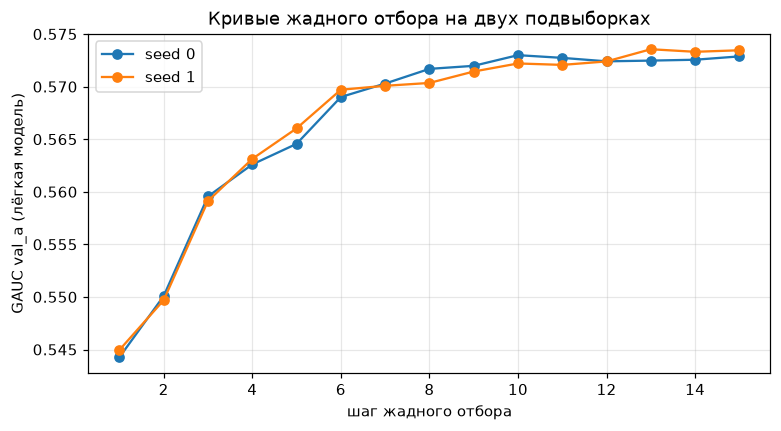

In [ ]:
steps1 = json.loads((ART / "greedy_nosess_seed1.json").read_text())
g0 = [s["added"] for s in res["greedy_steps"]]
g1 = [s["added"] for s in steps1]
k1 = int(np.argmax([s["gauc"] for s in steps1])) + 1       # пик GAUC на val_a — то же правило, что для seed 0
F1b = g1[:k1]

def meaning(f):
    parts = f.split("__")
    return f"{parts[0]}·{parts[1].split('_', 1)[-1]}"

side = pl.DataFrame({"шаг": range(1, max(len(g0), len(g1)) + 1),
                     "seed 0": g0 + [""] * (max(len(g0), len(g1)) - len(g0)),
                     "seed 1": g1 + [""] * (max(len(g0), len(g1)) - len(g1))})

display(side)

jac = lambda a, b: len(set(a) & set(b)) / len(set(a) | set(b))

print(f"Отобрано: seed 0 — {len(F1)} (пик на шаге {res['k_best']}), seed 1 — {k1}")
print(f"Жаккар (точно): {jac(F1, F1b):.2f}; общие: {sorted(set(F1) & set(F1b))}")
print(f"Жаккар (по смыслу ключ·агрегат): {jac([meaning(f) for f in F1], [meaning(f) for f in F1b]):.2f}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(g0) + 1), [s["gauc"] for s in res["greedy_steps"]], "o-", label="seed 0")
plt.plot(range(1, len(g1) + 1), [s["gauc"] for s in steps1], "o-", label="seed 1")
plt.xlabel("шаг жадного отбора")
plt.ylabel("GAUC val_a (лёгкая модель)")
plt.legend()
plt.title("Кривые жадного отбора на двух подвыборках")
plt.show()

**Качество набора seed 1** — та же лёгкая модель на одной и той же подвыборке train (seed 0), чтобы сравнивать только наборы признаков.

In [ ]:
tr_s = cands.filter(pl.col("part") == "train").sample(600_000, seed=0).sort("row_id")
va_c = cands.filter(pl.col("part") == "val_a")

need = sorted(set(F1) | set(F1b))
M = {n: load_matrix(d, need, cat).join(feats0, on="row_id", how="left", maintain_order="left")
     for n, d in [("tr", tr_s), ("va", va_c), ("vb", vb_c)]}

rows = []

for name, cols in [("E1 seed 0", F1), ("E1 seed 1", F1b), ("E0", E0_FEATURES)]:
    m = fit_light(M["tr"].select(cols).to_numpy(), tr_s["label"].to_numpy(), M["va"].select(cols).to_numpy(), va_c["label"].to_numpy())

    for part, d, key in [("val_a", va_c, "va"), ("val_b", vb_c, "vb")]:
        p = m.predict(M[key].select(cols).to_numpy(), num_iteration=m.best_iteration)
        rows.append({"набор": name, "признаков": len(cols), "часть": part,
                     **evaluate(d.select("uid", "day", "label").with_columns(p=pl.Series(p)), "p")})


stab = pl.DataFrame(rows)
del M
stab.select("набор", "признаков", "часть", *[pl.col(c).round(4) for c in ["logloss", "roc_auc", "gauc", "ndcg@10"]])

набор,признаков,часть,logloss,roc_auc,gauc,ndcg@10
str,i64,str,f64,f64,f64,f64
"""E1 seed 0""",10,"""val_a""",0.4681,0.821,0.573,0.7605
"""E1 seed 0""",10,"""val_b""",0.4635,0.8189,0.568,0.7638
"""E1 seed 1""",13,"""val_a""",0.4596,0.8287,0.5712,0.7607
"""E1 seed 1""",13,"""val_b""",0.4545,0.8272,0.5673,0.764
"""E0""",36,"""val_a""",0.4596,0.8284,0.5708,0.7583
"""E0""",36,"""val_b""",0.4564,0.8248,0.5665,0.7629


## 6. Выводы

**1. Как E1 использует признаки.** Самый сильный признак по общему вкладу — `ul__reco_srate__all` («как пользователь дослушивает рекомендации такой длины»): на 90% это доля дослушиваний пользователя , то есть через ключ «пользователь × длина трека» автоматика «протащила» признак уровня пользователя, но с частью, которая меняется между треками. Внутри группы ранжируют пары «пользователь × артист» (`ua__all_played__all`), трек (`i__reco_srate__90d`) и «пользователь × трек» — как и в E0

**2. Что нового по сравнению с E0.** Часть признаков E1 — это признаки E0 в другой форме (`ui__all_full__all` = `ui_full_all`, ρ = 1.0; `ua__all_played__all` +- `ua_full_rate_all`, 0.99). Новое (|ρ| < 0.85):
- срезы **только по рекомендациям**: `ui__reco_srate__all`, `u__reco_skip__all` , `i__reco_srate__90d`  — как пользователь реагирует именно на рекомендованные треки;
- окно **90 дней** для пары «пользователь × трек» (`ui__all_played__90d`, 0.75): E0 знает только 7/30 дней и всю историю.

Это и даёт значимый прирост E0 + E1 над E0 (+0.004 GAUC).

**3. Калибровка.** Все три модели лежат на диагонали; на val_b у всех небольшой сдвиг вниз из-за роста доли label (дрейф). E1 хуже по LogLoss не из-за калибровки, а потому что **менее уверенна**: разброс прогнозов 0.245 против 0.250 у E0 — ей не хватает признаков уровня пользователя.

**4. Сегменты.**
- По длине истории пользователя E1 +- E0 везде, **кроме холодных**: GAUC 0.518 против 0.527. Все отобранные признаки E1 — длинные окна по истории; у холодных пользователей их нет, а в E0 есть признаки, которые работают и без истории. В E0 + E1 холодные тоже чуть хуже E0  — длинные окна там шумят.
- По знакомости и популярности трека E1 проигрывает E0 по ROC-AUC **равномерно** : нет сегмента, где он ломается, — это тот же эффект нехватки признаков пользователя, а не провал на каком-то типе треков, (ROC-AUC выше у редких треков) повторяется и у E1

**5. Стабильность отбора.** Повтор всей воронки на другой подвыборке дал **другие имена признаков** (Жаккар 0.15 — общие только 3 из 10–13), но **те же смыслы** (Жаккар по «ключ × агрегат» 0.55: снова пара «пользователь × трек» с дослушиваниями, доля трека, пропуски пользователя, «пользователь × длина», «пользователь × артист») и **то же качество** по GAUC. Варианты одного признака с разными окнами и фильтрами взаимозаменяемы, и жадный отбор выбирает между ними почти случайно. 

Вывод для отчёта: **стабилен результат (качество и типы признаков), а не конкретный список**; интерпретировать отдельные окна (например, «90 дней лучше 30») по одному прогону нельзя. Набор seed 1 лучше по LogLoss (0.455 против 0.464), потому что случайно захватил признаки уровня пользователя (`u__all_skip__all`, `u__reco_srate__7d`).
